In [1]:
file_name = "17L_2025_05_29_17_05_57"
file_path = rf"G:\My Drive\no headstage vids\17L"

output_video_path = rf"{file_path}\{file_name}_stitched.avi"
video1_path = rf"{file_path}\{file_name}_cam2.avi"
video2_path = rf"{file_path}\{file_name}_cam1.avi"
stitched_image_path = rf"{file_path}\{file_name}_stitched_image.jpg"

In [2]:
import cv2
import numpy as np

import matplotlib.pyplot as plt

def undistort_image(image, camera_matrix, dist_coeffs):
    """
    Undistort the given image using the camera matrix and distortion coefficients.
    """
    h, w = image.shape[:2]
    new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(camera_matrix, dist_coeffs, (w, h), 1, (w, h))
    undistorted_image = cv2.undistort(image, camera_matrix, dist_coeffs, None, new_camera_matrix)
    return undistorted_image

def display_with_grid(image, title):
    """
    Display the image with a grid overlay.
    """
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.xticks(np.arange(0, image.shape[1], 50))
    plt.yticks(np.arange(0, image.shape[0], 50))
    plt.grid(color='white', linestyle='--', linewidth=0.2)
    plt.show()

# # Load the first frame from two videos
# file_name = "17L_2025_05_27_15_20_41"
# video1_path = rf"F:\My Drive\no headstage vids\17L\{file_name}_cam2.avi"
# video2_path = rf"F:\My Drive\no headstage vids\17L\{file_name}_cam1.avi"

cap1 = cv2.VideoCapture(video1_path)
cap2 = cv2.VideoCapture(video2_path)

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

cap1.release()
cap2.release()

if not ret1 or not ret2:
    raise ValueError("Failed to read frames from one or both videos.")

# Example camera matrix and distortion coefficients (replace with actual calibration data)
camera_matrix1 = np.array([[800, 0, 640],
                          [0, 800, 360],
                          [0, 0, 1]], dtype=np.float32)
dist_coeffs1 = np.array([-0.1, 0.15, 0, 0], dtype=np.float32)

camera_matrix2 = np.array([[800, 0, 640],
                          [0, 800, 360],
                          [0, 0, 1]], dtype=np.float32)
dist_coeffs2 = np.array([-0.2, 0.1, 0, 0], dtype=np.float32)

# Undistort the images
undistorted_frame1 = undistort_image(frame1, camera_matrix1, dist_coeffs1)
undistorted_frame2 = undistort_image(frame2, camera_matrix2, dist_coeffs2)

# Display the images with grid overlay
display_with_grid(undistorted_frame1, "Undistorted Frame 1")
display_with_grid(undistorted_frame2, "Undistorted Frame 2")
display_with_grid(frame1, "Frame 1")
display_with_grid(frame2, "Frame 2")

ValueError: Failed to read frames from one or both videos.

In [31]:
video1_path

'G:\\My Drive\\no headstage vids\\17L\\17L_2025_05_29_17_05_57_cam2.avi'

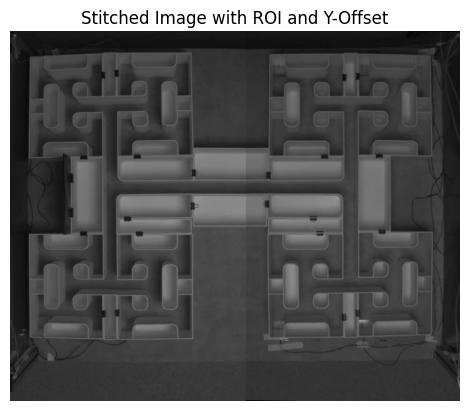

In [32]:
def stitch_images_with_roi_and_y_offset(img1, img2, roi1, roi2, y_offset1=0, y_offset2=0, resize_factor1=1.0, resize_factor2=1.0, rotation_angle1=0, rotation_angle2=0):
    """
    Stitch two images together with adjustable ROIs, resizing, rotation, and y-offset alignment.

    Parameters:
    - img1: First image.
    - img2: Second image.
    - roi1: Tuple (start_x, end_x) for img1.
    - roi2: Tuple (start_x, end_x) for img2.
    - y_offset1: Vertical offset for img1.
    - y_offset2: Vertical offset for img2.
    - resize_factor1: Scaling factor for img1.
    - resize_factor2: Scaling factor for img2.
    - rotation_angle1: Rotation angle for img1 in degrees.
    - rotation_angle2: Rotation angle for img2 in degrees.

    Returns:
    - stitched_image: The stitched image.
    """
    # Resize images
    img1_resized = cv2.resize(img1, None, fx=resize_factor1, fy=resize_factor1, interpolation=cv2.INTER_LINEAR)
    img2_resized = cv2.resize(img2, None, fx=resize_factor2, fy=resize_factor2, interpolation=cv2.INTER_LINEAR)

    # Rotate images
    def rotate_image(image, angle):
        h, w = image.shape[:2]
        center = (w // 2, h // 2)
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(image, rotation_matrix, (w, h))

    img1_rotated = rotate_image(img1_resized, rotation_angle1)
    img2_rotated = rotate_image(img2_resized, rotation_angle2)

    # Apply y-offsets
    def apply_y_offset(image, y_offset):
        if y_offset > 0:
            return image[y_offset:, :]
        elif y_offset < 0:
            return np.pad(image, ((-y_offset, 0), (0, 0), (0, 0)), mode='constant', constant_values=0)
        return image

    img1_aligned = apply_y_offset(img1_rotated, y_offset1)
    img2_aligned = apply_y_offset(img2_rotated, y_offset2)

    # Ensure both images have the same height
    height = min(img1_aligned.shape[0], img2_aligned.shape[0])
    img1_cropped = img1_aligned[:height, :]
    img2_cropped = img2_aligned[:height, :]

    # Apply ROIs
    img1_roi = img1_cropped[:, roi1[0]:roi1[1]]
    img2_roi = img2_cropped[:, roi2[0]:roi2[1]]

    # Adjust canvas size and stitch the images
    total_width = img1_roi.shape[1] + img2_roi.shape[1]
    canvas = np.zeros((height, total_width, 3), dtype=np.uint8)
    canvas[:, :img2_roi.shape[1]] = img2_roi
    canvas[:, img2_roi.shape[1]:] = img1_roi

    return canvas

# Example usage
roi1 = (510, 1100)  # Start and end x-coordinates for img1 (right)
roi2 = (300, 950)  # Start and end x-coordinates for img2 (left)
stitched_image = stitch_images_with_roi_and_y_offset(frame1, frame2, roi1, roi2, y_offset1=5, y_offset2=0, resize_factor1=1.0, resize_factor2=1.0, rotation_angle1=-1, rotation_angle2=0)

# Display the stitched image
plt.imshow(cv2.cvtColor(stitched_image, cv2.COLOR_BGR2RGB))
plt.title("Stitched Image with ROI and Y-Offset")
plt.axis('off')
plt.show()

In [ ]:
def enhance_image_histogram_balance(stitched_frame):
    """
    Enhance the input stitched image using histogram balancing (equalization).
    For color images, the luminance channel is equalized in the YCrCb color space.
    
    Parameters:
        stitched_frame (numpy.ndarray): Input image in BGR format.
    
    Returns:
        numpy.ndarray: Contrast-enhanced image.
    """
    # Check if the image is colored (3 channels) or grayscale.
    # if len(stitched_frame.shape) == 3 and stitched_frame.shape[2] == 3:
    #     # Convert to YCrCb color space.
    #     ycrcb = cv2.cvtColor(stitched_frame, cv2.COLOR_BGR2YCrCb)
    #     # Split the channels.
    #     y, cr, cb = cv2.split(ycrcb)
    #     # Apply histogram equalization on the Y channel.
    #     y_eq = cv2.equalizeHist(y)
    #     # Merge the channels back.
    #     ycrcb_eq = cv2.merge((y_eq, cr, cb))
    #     # Convert back to BGR.
    #     enhanced = cv2.cvtColor(ycrcb_eq, cv2.COLOR_YCrCb2BGR)
    # else:
    # For grayscale images, directly equalize the histogram.
    enhanced = cv2.equalizeHist(stitched_frame)
    
    return enhanced

# Example usage:
# enhanced_frame = enhance_image_histogram_balance(stitched_frame)

In [25]:
# export the stitched_image to a file
cv2.imwrite(rf"{file_path}\{file_name}.png", stitched_image)

True

In [ ]:
# # Define the output video path and parameters
# output_video_path = rf"{file_path}\{file_name}_stitched.mp4"
# frame_width = stitched_image.shape[1]
# frame_height = stitched_image.shape[0]
# fps = 40  # Frames per second

# # Initialize the VideoWriter
# # You can use other codecs like 'MJPG', 'DIVX', or 'H264' instead of 'XVID'
# # fourcc = cv2.VideoWriter_fourcc(*'DIVX')  # Example: Using MJPG codec
# fourcc = cv2.VideoWriter_fourcc(*'MJPG')
# out = cv2.VideoWriter(output_video_path, fourcc, fps, (frame_width, frame_height))

# # Reopen the video files
# cap1 = cv2.VideoCapture(video1_path)
# cap2 = cv2.VideoCapture(video2_path)

# while True:
#     ret1, frame1 = cap1.read()
#     ret2, frame2 = cap2.read()

#     if not ret1 or not ret2:
#         break

#     # Stitch the frames using the defined parameters
#     stitched_frame = stitch_images_with_roi_and_y_offset(
#         frame1, frame2, roi1, roi2, y_offset1=5, y_offset2=0,
#         resize_factor1=1.0, resize_factor2=1.0, 
#         rotation_angle1=-1, rotation_angle2=0
#     )

#     # Write the stitched frame to the output video
#     out.write(stitched_frame)

# # Release resources
# cap1.release()
# cap2.release()
# out.release()

# print(f"Stitched video saved to {output_video_path}")

Stitched video saved to G:\My Drive\no headstage vids\17L\17L_2025_05_29_17_05_57_stitched.mp4


In [7]:
stitched_image.shape[2]

3

In [ ]:
print(cv2.getBuildInformation())

In [ ]:
import cv2
import os
import numpy as np

# Define intermediate and final output paths
temp_output_path = rf"C:\Users\Almog\Documents\GitHub\MazeToGraph\{file_name}_stitched_temp.avi"
final_output_path = rf"{file_path}\{file_name}_stitched_enhanced.mp4"

# Reopen the video files
cap1 = cv2.VideoCapture(video1_path, cv2.CAP_FFMPEG)
cap2 = cv2.VideoCapture(video2_path, cv2.CAP_FFMPEG)

fps1 = cap1.get(cv2.CAP_PROP_FPS)
fps2 = cap2.get(cv2.CAP_PROP_FPS)

# Use average or select one if slightly off
fps = int(round((fps1 + fps2) / 2)) if abs(fps1 - fps2) < 1 else 40

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

if not ret1 or not ret2:
    raise ValueError("Error reading the first frames from the videos.")

# Check for size mismatch
if frame1.shape[:2] != frame2.shape[:2]:
    print("Warning: Input videos have different resolutions. Resizing second frame to match the first.")
    frame2 = cv2.resize(frame2, (frame1.shape[1], frame1.shape[0]))

# First stitched frame for dimensions
stitched_image = stitch_images_with_roi_and_y_offset(
    frame1, frame2, roi1, roi2,
    y_offset1=5, y_offset2=0,
    resize_factor1=1.0, resize_factor2=1.0,
    rotation_angle1=-1, rotation_angle2=0
)

frame_height, frame_width = stitched_image.shape[:2]

# Use FFV1 lossless codec for temporary output
fourcc = cv2.VideoWriter_fourcc(*'FFV1')
out = cv2.VideoWriter(temp_output_path, fourcc, fps, (frame_width, frame_height))

# Write first stitched frame
out.write(stitched_image)

# Continue processing the rest of the video
while True:
    ret1, frame1 = cap1.read()
    ret2, frame2 = cap2.read()

    if not ret1 or not ret2:
        break

    if frame1.shape[:2] != frame2.shape[:2]:
        frame2 = cv2.resize(frame2, (frame1.shape[1], frame1.shape[0]))

    stitched_frame = stitch_images_with_roi_and_y_offset(
        frame1, frame2, roi1, roi2,
        y_offset1=5, y_offset2=0,
        resize_factor1=1.0, resize_factor2=1.0,
        rotation_angle1=-1, rotation_angle2=0
    )

    stitched_frame = cv2.equalizeHist(stitched_frame)  # Enhance the stitched frame

    out.write(stitched_frame)

cap1.release()
cap2.release()
out.release()

print(f"Temporary lossless video saved to {temp_output_path}")

Temporary lossless video saved to C:\Users\Almog\Documents\GitHub\MazeToGraph\17L_2025_05_29_17_05_57_stitched_temp.avi


In [27]:
import subprocess

ffmpeg_cmd = [
    'ffmpeg',
    '-i', temp_output_path,
    '-c:v', 'libx264',
    '-crf', '18',
    '-preset', 'slow',
    final_output_path
]
subprocess.run(ffmpeg_cmd, check=True)
# # Clean up temporary file
# if os.path.exists(temp_output_path):
#     os.remove(temp_output_path)

print(f"Final stitched video saved to {final_output_path}")

Final stitched video saved to G:\My Drive\no headstage vids\18R\18R_2025_06_29_15_43_01_stitched.mp4


In [28]:
# Clean up temporary file
if os.path.exists(temp_output_path):
    os.remove(temp_output_path)